In [1]:
import io
import numpy as np
import pandas as pd
from PIL import Image

import tensorflow as tf
import pandas as pd
import numpy as np
from sklearn import preprocessing
from sklearn.model_selection import train_test_split
import sklearn.datasets as datasets
from tensorflow import keras

from keras.models import Sequential
from keras import layers

import matplotlib.pyplot as pt

In [2]:
splits = {'train': 'data/train-00000-of-00001-1359597a978bc4fa.parquet',
          'valid': 'data/valid-00000-of-00001-70d52db3c749a935.parquet'}
base = "hf://datasets/zh-plus/tiny-imagenet/"

def to_arrays(df):
    X = np.stack([
        np.array(Image.open(io.BytesIO(d['bytes'])).convert('RGB'))
        for d in df['image']
    ])
    y = df['label'].to_numpy()
    return X, y


In [3]:
X_train, y_train = to_arrays(pd.read_parquet(base + splits["train"]))
X_val, y_val = to_arrays(pd.read_parquet(base + splits["valid"]))

print(X_train.shape, y_train.shape)  # (100000, 64, 64, 3) (100000,)
print(X_val.shape, y_val.shape)  # (10000, 64, 64, 3) (10000,)

(100000, 64, 64, 3) (100000,)
(10000, 64, 64, 3) (10000,)


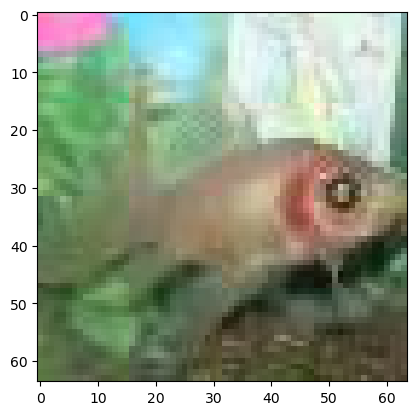

In [20]:
pt.imshow(X_train[0])

In [21]:
X_train = X_train.astype(np.float32) / 255

In [22]:
np.unique(y_train).shape

(200,)

In [23]:
import Utility as util

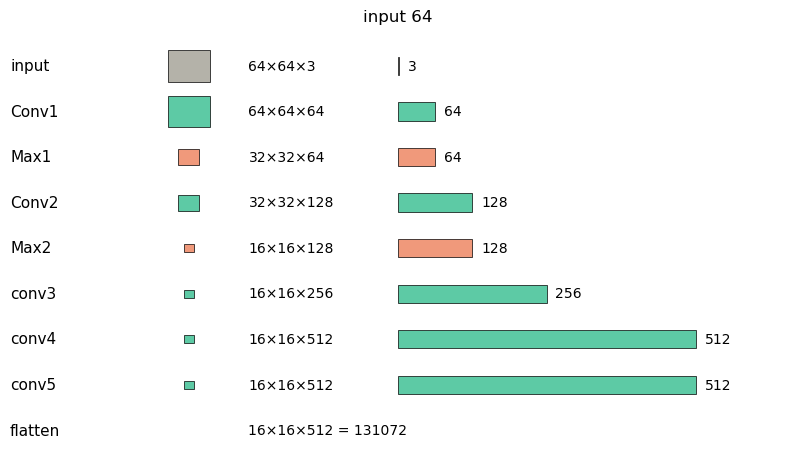

In [24]:
calc = (
    util.ShapeCalculator(64,3)
       .conv("Conv1", kernel=2, pad="same", filters=64)
       .pool("Max1", 2)
       .conv("Conv2", kernel=2, pad="same", filters=128)
       .pool("Max2", 2)
       .conv("conv3", kernel=3, pad="same", filters=256)
       .conv("conv4", kernel=3, pad="same", filters=512)
       .conv("conv5", kernel=3, pad="same", filters=512)
)

calc.plot()

In [31]:
model = Sequential(
    [
        layers.Conv2D(64, 2, padding="same", activation="relu"),
        layers.MaxPooling2D(2),
        layers.Conv2D(128, 2, padding="same", activation="relu"),
        layers.MaxPooling2D(2),
        layers.Conv2D(256, 2, padding="same", activation="relu"),
        layers.Conv2D(512, 2, padding="same", activation="relu"),
        layers.Conv2D(512, 2, padding="same", activation="relu"),
        layers.Flatten(),
        layers.Dense(4096, activation="relu"),
        layers.Dense(4096, activation="relu"),
        layers.Dense(200, activation="softmax")
    ]
)

In [32]:
model.compile(optimizer='adam', loss= 'sparse_categorical_crossentropy' , metrics=['accuracy'])

In [33]:
hist = model.fit(X_train, y_train, validation_split=0.1 , epochs= 10 , batch_size= 32)

Epoch 1/10
 364/2813 ━━━━━━━━━━━━━━━━━━━━ 2:12:27 3s/step - accuracy: 0.0053 - loss: 5.4388

KeyboardInterrupt: 